# Midpoint training on your GPU server
Run from the repository root after installing requirements. Both experiments train only t=0.5.
The supplied dataset has 500 triplets. We use 400 training, 50 validation and 50 held-out test triplets.
If multiple triplets originate from the same video, create a grouped split JSON first to avoid leakage between related scenes; pass it as `--split-file` to both runs.


In [3]:
import torch
print(torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name())

True
GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU


In [8]:
from pathlib import Path
import sys, subprocess, json
from IPython.display import display, Image
ROOT = Path.cwd()
assert (ROOT / 'scripts/finetune.py').exists(), 'Start Jupyter from the repository root'
CHECKPOINT = 'checkpoints/SuperSloMo.ckpt'
DEVICE = 'cuda'

def train(out, epochs, lr, extra):
    cmd = [sys.executable, 'scripts/finetune.py', '--dataset', 'dataset/train',
           '--num-train', '400', '--num-val', '50', '--num-test', '50',
           '--epochs', str(epochs), '--batch-size', '4', '--crop', '256', '256',
           '--workers', '2', '--device', DEVICE, '--amp', '--cosine',
           '--lr', str(lr), '--out', out, *extra]
    result = subprocess.run(
    cmd,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    )
    print(result.stdout)
    result.check_returncode()
# Reduce crop if your images are smaller, or batch size if GPU memory is limited.


## Fine-tune pretrained weights
Start with 20 epochs as an experiment budget; validation selects the best model, including epoch zero. Remove `--freeze-flow` to adapt both networks.

In [16]:
train('runs/midpoint_finetune', 20, 1e-5, ['--checkpoint', CHECKPOINT, '--freeze-flow'])

epoch 0 (before fine-tuning): val PSNR 27.286  SSIM 0.8867  (N=50)
epoch 1 step 0/100 loss 0.0881 recon 0.0281 lr 1.00e-05
epoch 1 step 25/100 loss 0.0421 recon 0.0134 lr 1.00e-05
epoch 1 step 50/100 loss 0.0507 recon 0.0141 lr 9.98e-06
epoch 1 step 75/100 loss 0.0603 recon 0.0136 lr 9.96e-06
epoch 1: train loss 0.0596  val PSNR 33.805  SSIM 0.9554  (24s)
  new best -> runs\midpoint_finetune\best.pt
epoch 2 step 0/100 loss 0.0617 recon 0.0140 lr 9.94e-06
epoch 2 step 25/100 loss 0.0648 recon 0.0136 lr 9.90e-06
epoch 2 step 50/100 loss 0.0731 recon 0.0164 lr 9.86e-06
epoch 2 step 75/100 loss 0.0308 recon 0.0049 lr 9.81e-06
epoch 2: train loss 0.0545  val PSNR 34.049  SSIM 0.9572  (26s)
  new best -> runs\midpoint_finetune\best.pt
epoch 3 step 0/100 loss 0.0605 recon 0.0127 lr 9.75e-06
epoch 3 step 25/100 loss 0.0448 recon 0.0096 lr 9.69e-06
epoch 3 step 50/100 loss 0.0501 recon 0.0100 lr 9.62e-06
epoch 3 step 75/100 loss 0.0374 recon 0.0079 lr 9.54e-06
epoch 3: train loss 0.0540  val PS

In [13]:
from pathlib import Path

p = Path(CHECKPOINT)
print("Path:", p.resolve())
print("Exists:", p.is_file())
if p.is_file():
    print("Size:", p.stat().st_size / (1024**2), "MB")

Path: D:\Avyay\sem_7\dip_project\checkpoints\SuperSloMo.ckpt
Exists: True
Size: 151.1172857284546 MB


## Train the reference model from scratch
Both U-Nets start with random weights. 100 epochs is an initial experiment budget, not a convergence guarantee. This small dataset may overfit. Reuse the exact split for a fair comparison.

In [ ]:
train('runs/midpoint_scratch', 100, 1e-4, ['--scratch', '--split-file', 'runs/midpoint_finetune/split.json'])

## Curves, before/after predictions, estimated flow and visibility
Error maps use a fixed [0,1] range. Optical flow is predicted by the model; there is no flow ground truth in these triplets. Test scores are for final reporting, not hyperparameter selection.

In [ ]:
for run in ['runs/midpoint_finetune', 'runs/midpoint_scratch']:
    print(run)
    display(Image(filename=str(Path(run) / 'curves.png')))
    for group in ['before', 'after', 'test']:
        for filename in sorted((Path(run) / group).glob('*.png')):
            print(group, filename.stem)
            display(Image(filename=str(filename)))
    print(json.loads((Path(run) / 'test_metrics.json').read_text()))
    history = json.loads((Path(run) / 'history.json').read_text())
    durations = [h['time_s'] for h in history if h['epoch'] > 0]
    if durations:
        print(f'Mean epoch time: {sum(durations)/len(durations):.1f}s')


## Inspect any held-out sample or predict a single midpoint

In [ ]:
import torch
from superslomo.checkpoint import build_model_from_checkpoint
from superslomo.data import FolderTriplet
from superslomo.training_viz import save_diagnostics
from superslomo.preprocess import rgb_to_tensor, load_image_rgb, tensor_to_rgb
model, metadata = build_model_from_checkpoint('runs/midpoint_finetune/best.pt', DEVICE)
split = json.loads(Path('runs/midpoint_finetune/split.json').read_text())
test = FolderTriplet('dataset/train', split['test'])
import matplotlib.pyplot as plt
figures = save_diagnostics(model, test, device=DEVICE, index=0)
for figure in figures.values():
    display(figure)
    plt.close(figure)
b = test[0]
with torch.no_grad():
    midpoint = model.interpolate(b['I0'][None].to(DEVICE), b['I1'][None].to(DEVICE), [0.5])[0]
display(Image(data=__import__('cv2').imencode('.png', tensor_to_rgb(midpoint)[0][..., ::-1])[1].tobytes()))


## Test an existing best.pt without retraining
Run this independently after defining ROOT/imports, or use the same command in a terminal. Scores use the saved held-out split; each diagnostic is saved as a separate PNG.

In [17]:
import subprocess, sys
subprocess.run([sys.executable, 'scripts/evaluate_midpoint.py',
    '--checkpoint', 'runs/midpoint_finetune/best.pt',
    '--dataset', 'dataset/train',
    '--split-file', 'runs/midpoint_finetune/split.json',
    '--device', 'cuda', '--visualize', '3',
    '--out', 'outputs/midpoint_test'], check=True)


CompletedProcess(args=['d:\\Avyay\\sem_7\\dip_project\\.venv\\Scripts\\python.exe', 'scripts/evaluate_midpoint.py', '--checkpoint', 'runs/midpoint_finetune/best.pt', '--dataset', 'dataset/train', '--split-file', 'runs/midpoint_finetune/split.json', '--device', 'cuda', '--visualize', '3', '--out', 'outputs/midpoint_test'], returncode=0)

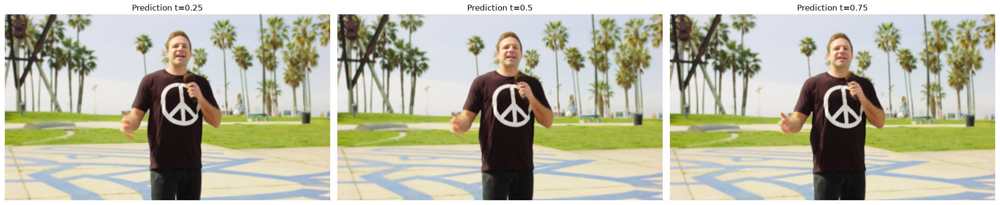

In [27]:
from superslomo.inference import Interpolator
import matplotlib.pyplot as plt

interp=Interpolator.from_checkpoint(
    'superslomo',
    "runs/midpoint_finetune/best.pt",
    device='cuda',
)


import cv2
img1=cv2.imread(r'dataset\train\imgdata_149\im1.png')
img2=cv2.imread(r'dataset\train\imgdata_149\im3.png')

img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)

times=[0.25,0.5,0.75]

res=interp(img1,img2,[0.25,0.5,0.75])

fig, axes = plt.subplots(1, 3, figsize=(21, 7))
for ax, frame, t in zip(axes, res, times):
    ax.imshow(frame)
    ax.set_title(f"Prediction t={t}")
    ax.axis("off")

plt.tight_layout()
plt.savefig('pred1.png',dpi=300)
plt.show()

In [28]:
from pathlib import Path

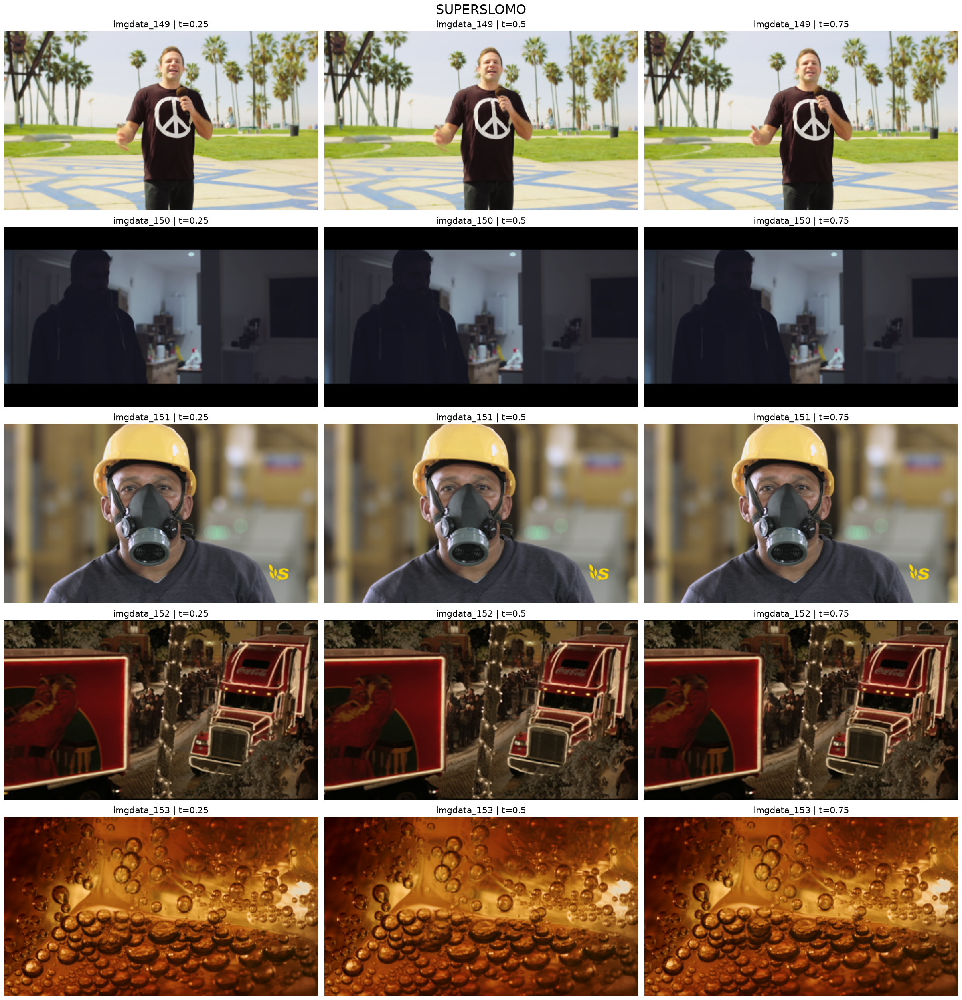

Saved: outputs\method_comparison_149_153\superslomo_comparison.png


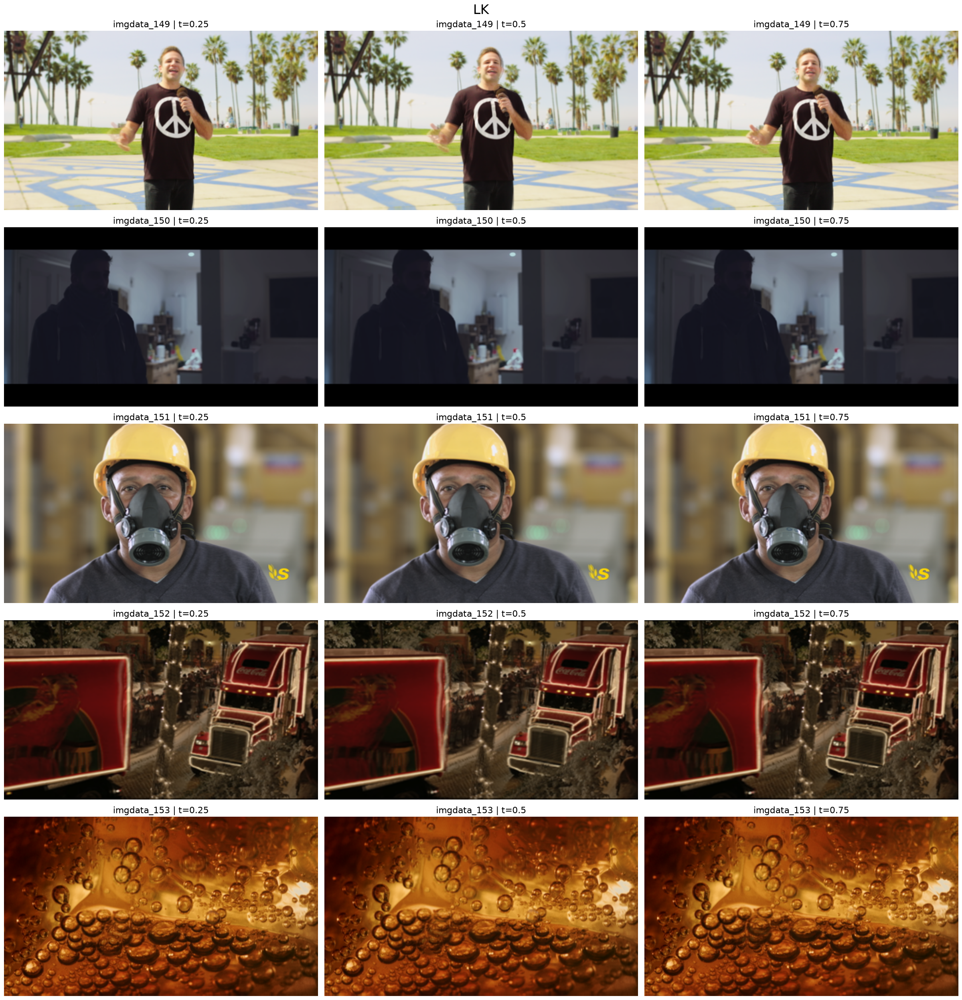

Saved: outputs\method_comparison_149_153\lk_comparison.png


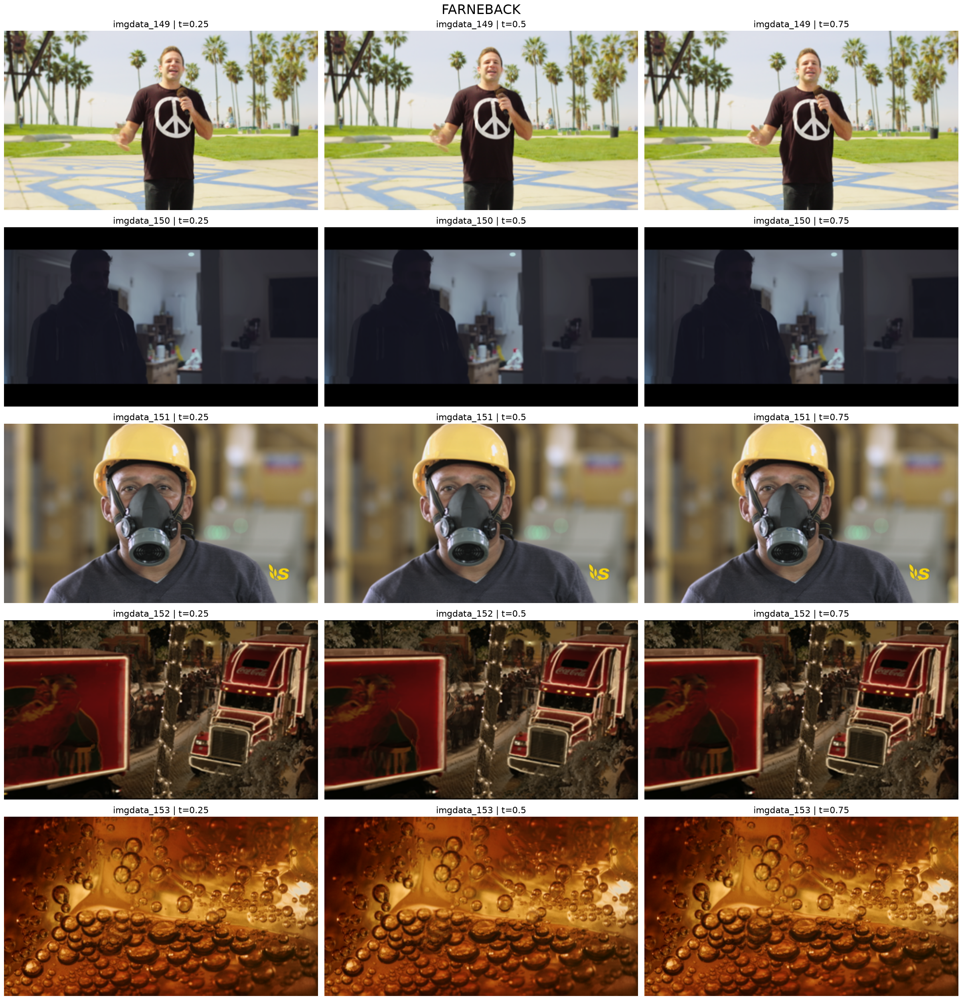

Saved: outputs\method_comparison_149_153\farneback_comparison.png


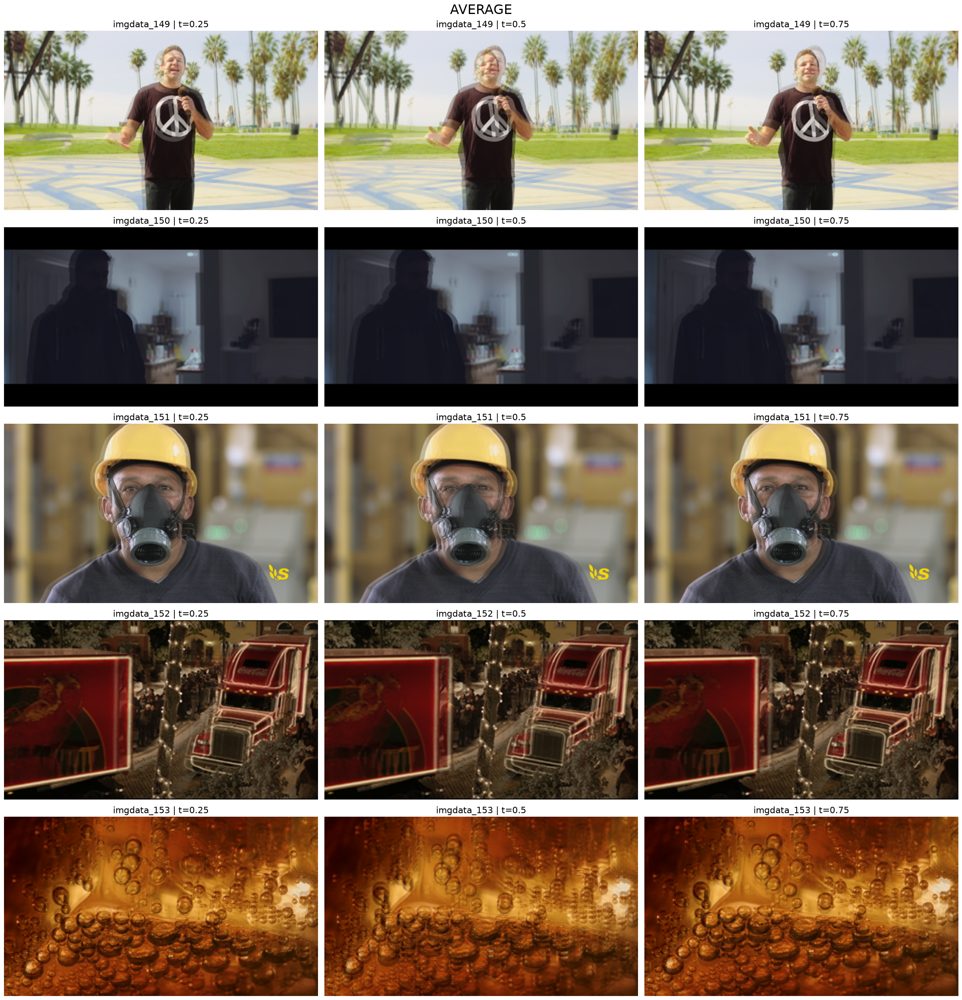

Saved: outputs\method_comparison_149_153\average_comparison.png


In [29]:

dataset = Path("dataset/train")
out = Path("outputs/method_comparison_149_153")
out.mkdir(parents=True, exist_ok=True)

sample_ids = range(149, 154)
times = [0.25, 0.5, 0.75]

methods = {
    "superslomo": Interpolator.from_checkpoint(
        "superslomo",
        "runs/midpoint_finetune/best.pt",
        device="cuda",
    ),
    "lk": Interpolator("lk"),
    "farneback": Interpolator("farneback"),
    "average": Interpolator("average"),
}


def read_rgb(path):
    image = cv2.imread(str(path))
    if image is None:
        raise FileNotFoundError(f"Could not read: {path.resolve()}")
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


# Read endpoints once; im2 is not used for prediction.
pairs = {}
for sample_id in sample_ids:
    folder = dataset / f"imgdata_{sample_id}"
    pairs[sample_id] = (
        read_rgb(folder / "im1.png"),
        read_rgb(folder / "im3.png"),
    )

for method, interpolator in methods.items():
    method_out = out / method
    method_out.mkdir(parents=True, exist_ok=True)

    fig, axes = plt.subplots(
        len(pairs), len(times),
        figsize=(24, 25),
        squeeze=False,
        layout="constrained",
    )

    for row, (sample_id, (img1, img3)) in enumerate(pairs.items()):
        predictions = interpolator(img1, img3, times)

        for col, (t, frame) in enumerate(zip(times, predictions)):
            ax = axes[row, col]
            ax.imshow(frame)
            ax.set_title(f"imgdata_{sample_id} | t={t}", fontsize=16)
            ax.axis("off")

            # OpenCV expects BGR when saving.
            filename = method_out / f"imgdata_{sample_id}_t{t:.2f}.png"
            saved = cv2.imwrite(
                str(filename),
                cv2.cvtColor(frame, cv2.COLOR_RGB2BGR),
            )
            if not saved:
                raise OSError(f"Could not save: {filename}")

    fig.suptitle(method.upper(), fontsize=24)
    figure_path = out / f"{method}_comparison.png"
    fig.savefig(figure_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved: {figure_path}")